<a href="https://colab.research.google.com/github/2022245/ai-employment-analysis./blob/main/1_AI_Employment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI, Data Science and Software Development Employment Analysis

**Student name:** Marco Rubio Lira
**Student ID:** 2022245

**GitHub repository:** https://github.com/2022245/ai-employment-analysis.

**Video Link:** https://drive.google.com/file/d/1ZXdAFgaioF1kjsHyd2_nTvb4G8DLFzLn/view?usp=drive_link

## Introduction

This notebook explores employment and wages in occupations related to AI, Data Science and Software Development in the USA. It uses employment data from May 2023 published by the US Bureau of Labor Statistics.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [15]:
import pandas as pd

df = pd.read_excel("/content/all_data_M_2023.xlsx")

df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [16]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (413327, 32)

Column names:
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


In [17]:
occupations = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information Research Scientists"
]

national = df[
    (df["AREA_TITLE"] == "U.S.") &
    (df["NAICS"].astype(str) == "000000") &
    (df["OWN_CODE"].astype(str) == "1235") &
    (df["OCC_TITLE"].isin(occupations))
].copy()

national[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]]

,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN
137,15-1220,Computer and Information Research Scientists,35210,157160
138,15-1221,Computer and Information Research Scientists,35210,157160
149,15-1252,Software Developers,1656880,138110
164,15-2050,Data Scientists,192710,119040
165,15-2051,Data Scientists,192710,119040


In [18]:
national = national[national["O_GROUP"] == "detailed"].copy()

national[["OCC_CODE", "OCC_TITLE", "TOT_EMP", "A_MEAN"]]

,OCC_CODE,OCC_TITLE,TOT_EMP,A_MEAN
138,15-1221,Computer and Information Research Scientists,35210,157160
149,15-1252,Software Developers,1656880,138110
165,15-2051,Data Scientists,192710,119040


In [19]:
national["TOT_EMP"] = pd.to_numeric(national["TOT_EMP"], errors="coerce")
national["A_MEAN"] = pd.to_numeric(national["A_MEAN"], errors="coerce")

print(national[["TOT_EMP", "A_MEAN"]].dtypes)
print("\nMissing values:")
print(national[["TOT_EMP", "A_MEAN"]].isna().sum())

TOT_EMP    int64
A_MEAN     int64
dtype: object

Missing values:
TOT_EMP    0
A_MEAN     0
dtype: int64


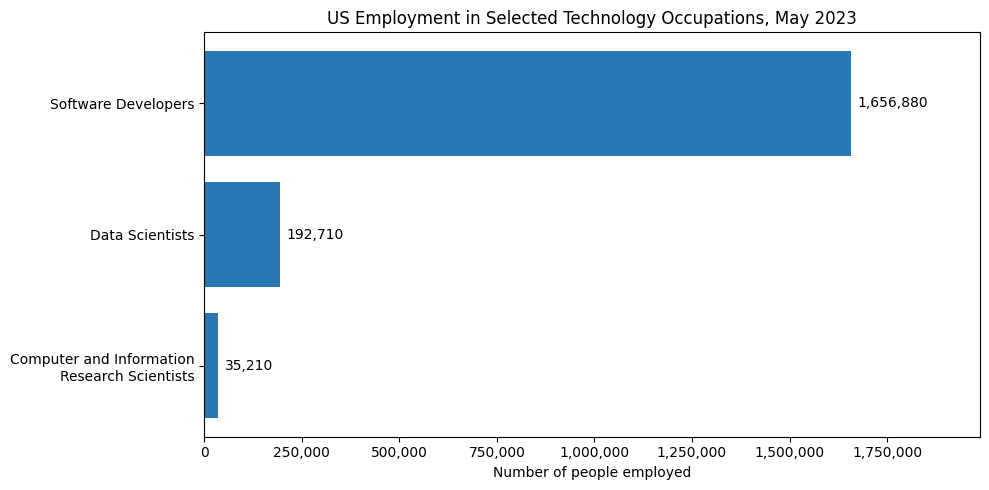

In [20]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

chart_data = national.sort_values("TOT_EMP")

labels = chart_data["OCC_TITLE"].replace({
    "Computer and Information Research Scientists": "Computer and Information\nResearch Scientists"
})

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(labels, chart_data["TOT_EMP"], color="#2878B5")

ax.bar_label(bars, fmt="{:,.0f}", padding=5)
ax.set_title("US Employment in Selected Technology Occupations, May 2023")
ax.set_xlabel("Number of people employed")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, chart_data["TOT_EMP"].max() * 1.2)

plt.tight_layout()
plt.show()

### Visualisation 1: Employment by occupation

**Objective:** Compare employment in three US occupations related to AI, Data Science and Software Development in May 2023.

**Why this chart:** A horizontal bar chart makes it easy to compare employment numbers across occupations. It also leaves enough space for the long occupation names.

**Findings:** Software Developers had the highest employment, with 1,656,880 people. Data Scientists had 192,710, while Computer and Information Research Scientists had 35,210. Software Developers employed about 8.6 times as many people as Data Scientists.

These figures cover the full occupations, so they do not show how many people worked specifically in AI. They also represent one point in time and cannot show employment growth.

In [21]:
states = df[
    (df["AREA_TYPE"] == 2) &
    (df["NAICS"].astype(str) == "000000") &
    (df["OWN_CODE"].astype(str) == "1235") &
    (df["O_GROUP"] == "detailed") &
    (df["OCC_TITLE"].isin(occupations))
].copy()

for column in ["TOT_EMP", "A_MEAN"]:
    states[column] = pd.to_numeric(states[column], errors="coerce")

print("Rows per occupation:")
print(states.groupby("OCC_TITLE").size())

print("\nMissing values:")
print(states[["TOT_EMP", "A_MEAN"]].isna().sum())

Rows per occupation:
OCC_TITLE
Computer and Information Research Scientists    42
Data Scientists                                 51
Software Developers                             51
dtype: int64

Missing values:
TOT_EMP    5
A_MEAN     0
dtype: int64


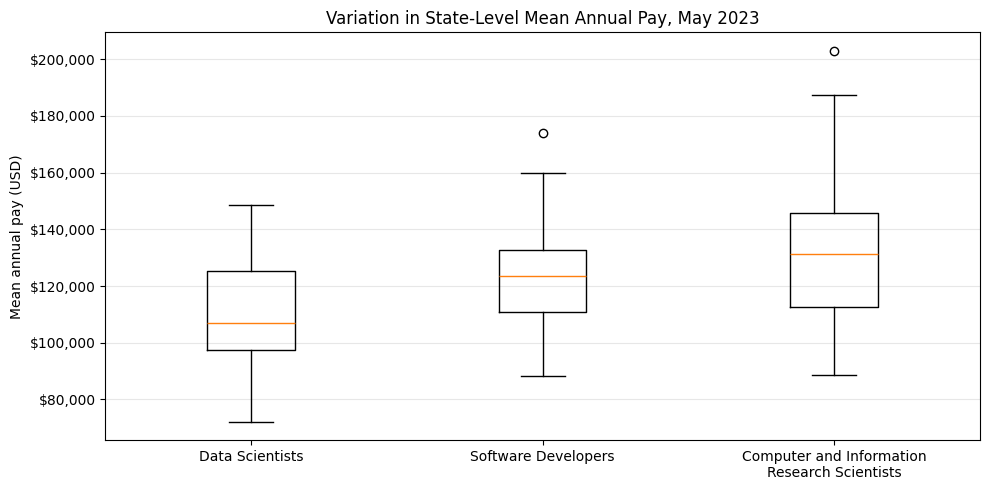

In [22]:
pay_data = [
    states.loc[states["OCC_TITLE"] == occupation, "A_MEAN"].dropna()
    for occupation in occupations
]

labels = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information\nResearch Scientists"
]

fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot(pay_data)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(labels)
ax.set_title("Variation in State-Level Mean Annual Pay, May 2023")
ax.set_ylabel("Mean annual pay (USD)")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Visualisation 2: Variation in state-level pay

**Objective:** Compare how mean annual pay varies across state level areas for the three selected occupations.

**Why this chart:** A box plot summarises the median, the middle 50% of values and the spread. It also highlights unusually high or low values, making it useful for comparing pay across locations.

**Findings:** Computer and Information Research Scientists had the highest median of state level mean pay, at approximately $131,000. Software Developers followed at around $124,000, while Data Scientists were around $107,000. Research Scientists also had the widest spread, suggesting larger differences in average pay between locations. The circles show unusually high area averages for Software Developers and Research Scientists.

Each value represents an area's mean pay, not an individual worker's salary. Areas are given equal weight regardless of employment size. The comparison uses 42 available areas for Research Scientists and 51 each for the other two occupations.

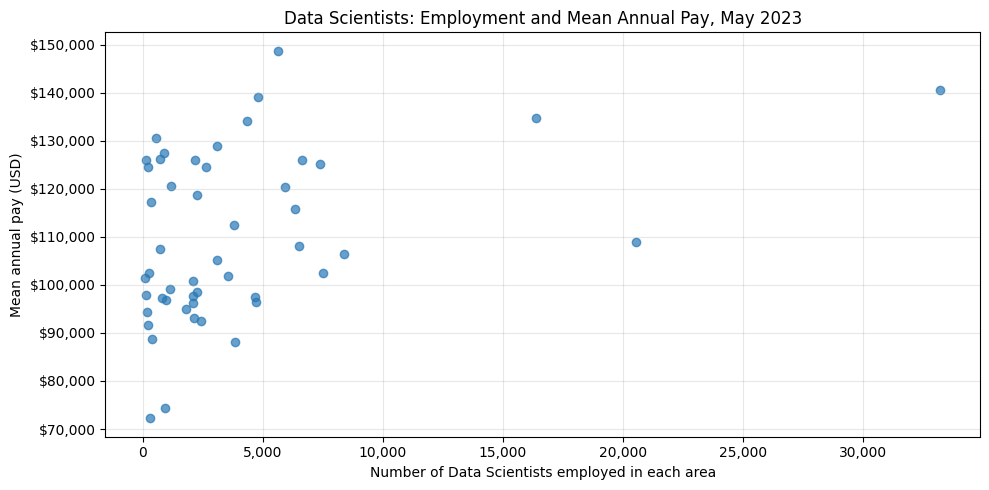

In [23]:
data_scientists = states[
    states["OCC_TITLE"] == "Data Scientists"
].dropna(subset=["TOT_EMP", "A_MEAN"]).copy()

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    data_scientists["TOT_EMP"],
    data_scientists["A_MEAN"],
    color="#2878B5",
    alpha=0.7
)

ax.set_title("Data Scientists: Employment and Mean Annual Pay, May 2023")
ax.set_xlabel("Number of Data Scientists employed in each area")
ax.set_ylabel("Mean annual pay (USD)")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Visualisation 3: Data Scientist employment and pay

**Objective:** Explore whether state level areas with more Data Scientists also have higher mean annual pay.

**Why this chart:** A scatter plot shows the relationship between two numerical variables: employment and mean annual pay. Each dot represents one area, making it possible to see patterns and unusual observations.

**Findings:** Most areas had fewer than 10,000 Data Scientists, but their average pay varied considerably. The area with the highest employment, around 33,000, had mean annual pay of approximately $141,000. However, the highest average pay, around $149,000, occurred in an area with roughly 5,600 Data Scientists. Higher employment therefore did not always correspond to higher pay.

The chart does not prove that employment levels cause pay differences. It also does not account for living costs, experience or industry differences between areas.

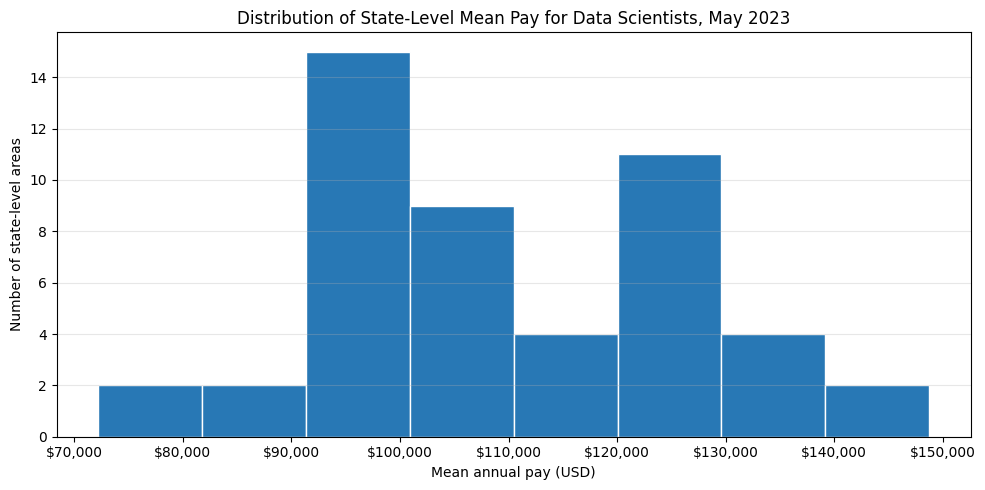

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    data_scientists["A_MEAN"],
    bins=8,
    color="#2878B5",
    edgecolor="white"
)

ax.set_title("Distribution of State-Level Mean Pay for Data Scientists, May 2023")
ax.set_xlabel("Mean annual pay (USD)")
ax.set_ylabel("Number of state-level areas")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Visualisation 4: Distribution of Data Scientist pay

**Objective:** Identify the most common ranges of state level mean annual pay for Data Scientists.

**Why this chart:** A histogram groups numerical pay values into ranges and counts the areas in each range. This makes it easier to see where average pay is concentrated.

**Findings:** The most common pay range was approximately $92,000–$101,000, covering 15 areas. Another concentration appeared around $121,000–$130,000, with 11 areas. Few areas were at the lowest or highest ends, although mean annual pay ranged from roughly $72,000 to $149,000.

These are area averages, not individual salaries. Each area counts equally, and changing the number of bins could change how the pattern looks.

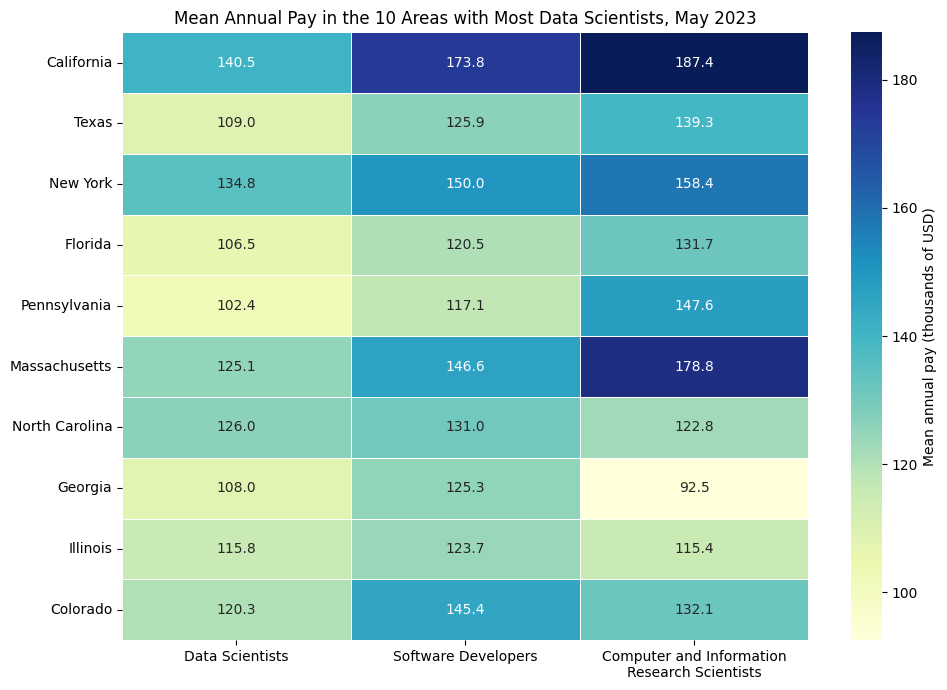

In [25]:
import seaborn as sns

top_areas = data_scientists.nlargest(10, "TOT_EMP")["AREA_TITLE"]

pay_table = states.pivot(
    index="AREA_TITLE",
    columns="OCC_TITLE",
    values="A_MEAN"
).reindex(index=top_areas, columns=occupations)

pay_table.columns = [
    "Data Scientists",
    "Software Developers",
    "Computer and Information\nResearch Scientists"
]

fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    pay_table / 1000,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Mean annual pay (thousands of USD)"},
    ax=ax
)

ax.set_title("Mean Annual Pay in the 10 Areas with Most Data Scientists, May 2023")
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

### Visualisation 5: Pay comparison across occupations and areas

**Objective:** Compare mean annual pay for the three occupations in the ten areas with the highest Data Scientist employment.

**Why this chart:** A heatmap makes it easy to compare several occupations and locations together. Darker colours indicate higher pay, while the numbers show the values in thousands of US dollars.

**Findings:** California had higher mean pay than Texas and New York across all three occupations. In California, Research Scientists earned approximately $187,400, Software Developers $173,800 and Data Scientists $140,500.

The pay ranking also differed between locations. In Georgia, Software Developers had higher mean pay than the other two occupations, while Research Scientists had the lowest. This shows that the national pay ranking does not apply to every area.

The ten areas were selected by Data Scientist employment, not by salary. These figures do not account for living costs or differences in workers' experience.

**Source:** Author's calculations using U.S. Bureau of Labor Statistics (n.d.a).

In [26]:
df_2021 = pd.read_excel("/content/all_data_M_2021.xlsx")
df_2022 = pd.read_excel("/content/all_data_M_2022.xlsx")

print("2021:", df_2021.shape)
print(df_2021.columns.tolist())

print("\n2022:", df_2022.shape)
print(df_2022.columns.tolist())

2021: (406359, 32)
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']

2022: (409859, 32)
['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


In [27]:
yearly_data = []

for year, dataset in [(2021, df_2021), (2022, df_2022), (2023, df)]:
    selected = dataset[
        (dataset["AREA_TITLE"] == "U.S.") &
        (dataset["NAICS"].astype(str) == "000000") &
        (dataset["OWN_CODE"].astype(str) == "1235") &
        (dataset["O_GROUP"] == "detailed") &
        (dataset["OCC_TITLE"].isin(occupations))
    ].copy()

    selected["YEAR"] = year
    selected["TOT_EMP"] = pd.to_numeric(selected["TOT_EMP"], errors="coerce")

    yearly_data.append(selected[["YEAR", "OCC_CODE", "OCC_TITLE", "TOT_EMP"]])

trends = pd.concat(yearly_data, ignore_index=True)

display(trends)

,YEAR,OCC_CODE,OCC_TITLE,TOT_EMP
0,2021,15-1221,Computer and Information Research Scientists,30840
1,2021,15-1252,Software Developers,1364180
2,2021,15-2051,Data Scientists,105980
3,2022,15-1221,Computer and Information Research Scientists,33780
4,2022,15-1252,Software Developers,1534790
5,2022,15-2051,Data Scientists,159630
6,2023,15-1221,Computer and Information Research Scientists,35210
7,2023,15-1252,Software Developers,1656880
8,2023,15-2051,Data Scientists,192710


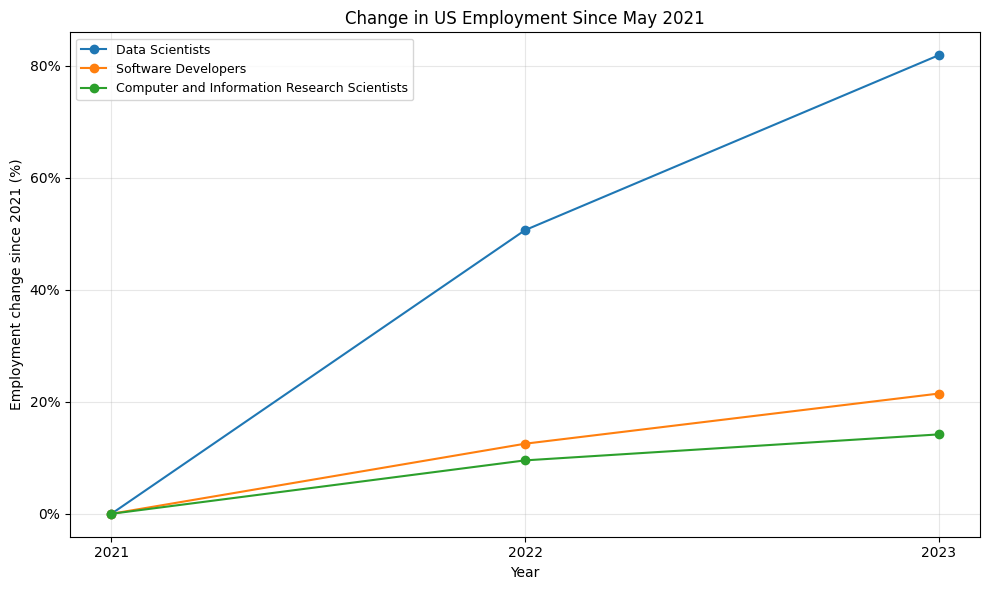

OCC_TITLE,Computer and Information Research Scientists,Data Scientists,Software Developers
YEAR,,,
2021,0.0,0.0,0.0
2022,9.5,50.6,12.5
2023,14.2,81.8,21.5


In [28]:
employment_by_year = trends.pivot(
    index="YEAR",
    columns="OCC_TITLE",
    values="TOT_EMP"
).sort_index()

growth = (
    employment_by_year / employment_by_year.loc[2021] - 1
) * 100

fig, ax = plt.subplots(figsize=(10, 6))

for occupation in occupations:
    ax.plot(
        growth.index,
        growth[occupation],
        marker="o",
        label=occupation
    )

ax.set_title("Change in US Employment Since May 2021")
ax.set_xlabel("Year")
ax.set_ylabel("Employment change since 2021 (%)")
ax.set_xticks([2021, 2022, 2023])
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
ax.grid(alpha=0.3)
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

display(growth.round(1))

### Visualisation 6: Employment trends, 2021–2023

**Objective:** Explore changes in national employment estimates for the three selected occupations using the May 2021, 2022 and 2023 datasets.

**Why this chart:** A line chart shows changes over time. Using percentage change from 2021 allows us to compare occupations with very different workforce sizes. All three lines start at 0%, representing their 2021 baseline.

**Findings:** Data Scientists showed the largest percentage increase, rising from 105,980 in 2021 to 192,710 in 2023, an increase of 81.8%. Software Developers increased by 21.5%, while Computer and Information Research Scientists increased by 14.2%.

However, Software Developers had the largest numerical increase: 292,700, compared with 86,730 for Data Scientists and 4,370 for Research Scientists. The fastest percentage increase therefore did not mean the largest number of additional jobs.

**Limitations:** These are comparisons of published employment estimates, rather than a count of newly created jobs. Annual OEWS estimates use overlapping survey periods, and changes in methods or occupational classification can affect comparisons. Matching occupation codes helps, but does not remove these limitations. These occupations include work beyond AI, so the results cannot show how much of the increase was caused by AI.

The BLS advises caution when comparing OEWS estimates over time because of these limitations (U.S. Bureau of Labor Statistics, n.d.b).

## Conclusion

Software Developers had the largest workforce among the three selected occupations in 2023. Computer and Information Research Scientists generally had higher average pay, although the ranking varied between locations. Data Scientists showed the largest percentage increase in employment estimates between 2021 and 2023, while Software Developers had the largest numerical increase.

Overall, the visualisations show differences in employment size, pay and changes over time. However, these occupations cover work beyond AI, so the findings cannot measure AI employment directly or prove that AI caused the increases.

## References

U.S. Bureau of Labor Statistics (n.d.a) *Occupational Employment and Wage Statistics (OEWS) tables*. May 2021, May 2022 and May 2023, All data datasets. Available at: https://www.bls.gov/oes/tables.htm (Accessed: 5 November 2026).

U.S. Bureau of Labor Statistics (n.d.b) *Frequently asked questions*. Available at: https://www.bls.gov/oes/oes_ques.htm (Accessed: 5 November 2026).